In [1]:
pip install engineering_notation

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from engineering_notation import EngNumber
from matplotlib.widgets import Slider, Button
from matplotlib.colors import Normalize
import matplotlib.cm as cm
import cmath
import matplotlib.colors as mcolors
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter,AutoMinorLocator)

# Dados do Transformador e do Filtro

# Dados Básicos

## Rede

In [3]:
V_fund = 34.5e3
f_fund = 60
w_fund = 2*np.pi*f_fund



## Potência reativa a corrigir em $60\,\rm{Hz}$

In [4]:
Q_filtro = 20e6
X_F      = V_fund**2 / Q_filtro

## Indutância e Capacitância do Filtro

In [5]:
h_filtrar = 5
flagDessintonia = True
if( flagDessintonia == True ):
    d = 2/100
else:
    d = 0
h_0 = (1-d)*h_filtrar
h02 = h_0**2

X_L =  1/(h02-1) * X_F
L   =  X_L / w_fund

X_C = h02/(h02-1) * X_F
C   = 1  / ( X_C* w_fund )

f_max = ( 1 / np.sqrt(L*C) ) / ( 2 * np.pi )
EngNumber(f_max)

294

## Dados do indutor, se fornecido

In [6]:
flagPerdasIndutor = True

if( flagPerdasIndutor == True ):
    P_perdasIndutor = 9.8e3 # perdas em um único indutor
    I_indutor = 572
    R_indutor = P_perdasIndutor / I_indutor**2
else:
    R_indutor = 0

## Fator de Qualidade e Amortecimento (Resistência do Filtro)

In [7]:
Z0 = np.sqrt(L/C)

flagFatorDeQualidade = False
if( flagFatorDeQualidade == True ):
    FQual = 80.0
    R = Z0 / FQual
else:
    R  = R_indutor
    FQual = Z0 / R

### Cálculo do circuito $RL$ dual paralelo

In [8]:
Z_RL = R + 1j*X_L
Y_RL = 1 / Z_RL
R_paralelo = 1 / np.real(Y_RL)
X_L_paralelo = - 1 / np.imag(Y_RL)
L_paralelo = X_L_paralelo / w_fund
Z_RLverdadeiro = R_indutor + 1j*X_L
Z_RLverdadeiro = 1 / Z_RLverdadeiro
# resistência somente devido ao indutor, idealmetne infinita em paralelo
R_parIndutor   = 1 / np.real(Z_RLverdadeiro)

## Dados do transformador, se fornecido

In [9]:
flagImpedanciaTrafo = True
if( flagImpedanciaTrafo == True ):
    S_trafo     = 60e6
    Z_baseTrafo = V_fund**2 / S_trafo

    impedânciaPercentual = 5/100

    Z_trafo     = 1j*impedânciaPercentual * Z_baseTrafo

## Variação com a frequência

In [10]:
nharm = 25
f = np.arange(f_fund, nharm*f_fund, f_fund)
f = np.round(f,4) # não tire este ROUND se houverem frequencias interharmônicas
w = 2*np.pi*f

### Filtro

In [11]:
Zfiltro = R + 1j*w*L + 1/(1j*w*C)
Zmod    = np.abs(Zfiltro)
Zang    = np.angle(Zfiltro, deg=True)

### Transformador

In [12]:
X_trafo     = ( np.imag(Z_trafo)/w_fund ) * w
R_trafo     =   np.real(Z_trafo)          * np.ones(len(w))
Z_trafoFreq =   R_trafo + 1j*X_trafo

## Filtro em paralelo com o transformador

In [13]:
Y_filtro      = 1 / Zfiltro
Y_trafo       = 1 / Z_trafoFreq
Y_trafoFiltro = Y_filtro + Y_trafo
Z_trafoFiltro = 1 / Y_trafoFiltro

## Correntes harmônicas prezumidas

In [14]:
Y_trafoCapaci = 1j*w*C + 1/Z_trafoFreq
Z_trafoCapaci = 1 / Y_trafoCapaci
I_baseTrafo   = S_trafo / ( V_fund * np.sqrt(3) )

In [15]:
iharm      = np.zeros((len(f)), dtype=np.complex_)
vharmCF    = np.zeros((len(f)), dtype=np.complex_)
vharmSF    = np.zeros((len(f)), dtype=np.complex_)
iharmF     = np.zeros((len(f)), dtype=np.complex_)
iharmTCF   = np.zeros((len(f)), dtype=np.complex_)

iharmint     = np.zeros(nharm)
vharmintCF   = np.zeros(nharm)
vharmintSF   = np.zeros(nharm)
itrafoint    = np.zeros(nharm)
freqint      = np.zeros(nharm, dtype=int)

Z_trafoCapaciint   = np.zeros((len(f)), dtype=np.complex_)

flagCorrenteFiltro = False

itotalfiltro = 0
for k in range(len(f)):
    harm          = f[k] /f_fund
    
    if( flagCorrenteFiltro == True ):
        iharm[k]    = I_baseTrafo / harm
        vharmCF[k]  = iharm[k] * Z_trafoFiltro[k]
        vharmSF[k]  = iharm[k] * Z_trafoCapaci[k]
        iharmF[k]   = vharmCF[k] / Zfiltro[k]
        iharmTCF[k] = vharmCF[k] / Z_trafoFreq[k]

        freqint[k]     =   harm*f_fund
        iharmint[k]    =   np.abs(iharmF[k])
        vharmintCF[k]  =   np.abs(vharmCF[k])
        vharmintSF[k]  =   np.abs(vharmSF[k])
        itotalfiltro   =   itotalfiltro + (np.abs(iharmF[k]))**2
        itrafoint      =   np.abs(iharmTCF[k])

        Z_trafoCapaciint[k] = Z_trafoCapaci[k]

    if( flagCorrenteFiltro == False ):
        freqint[k]     =      harm*f_fund
        if( k!=0 and k!=h_filtrar-1 ):
            iharmint[k]    =   0.05 * ( S_trafo /3 ) / ( V_fund/np.sqrt(3) ) / harm
        else:
            # corrente @ 60Hz para corrigir reativos
            iharmint[0]           = 1.0 * ( Q_filtro/3 ) / ( V_fund/np.sqrt(3) )
            # corrente da harmônica h_filtrar = metade da corrente fundamental total
            iharmint[h_filtrar-1] = 0.5 * I_baseTrafo
        iharmF[k]      =    iharmint[k]
        vharmintCF[k]  =   np.abs( iharmF[k] * Z_trafoFiltro[k] )
        vharmintSF[k]  =   np.abs( iharmF[k] * Z_trafoCapaci[k] )
        itotalfiltro   =   itotalfiltro + (np.abs(iharmF[k]))**2
        itrafoint[k]   =   np.abs(iharmTCF[k])


itotalfiltro=np.sqrt(itotalfiltro)            

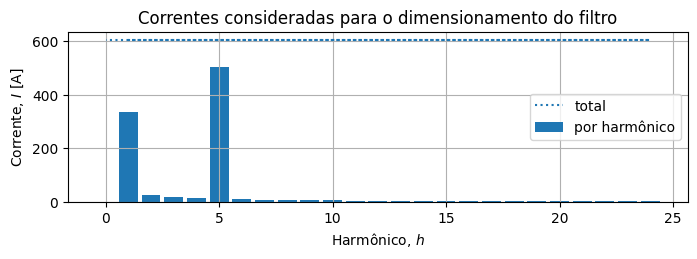

In [16]:
plt.figure(dpi=100, figsize=(16/2,9/4))
plt.bar (freqint/f_fund,iharmint, 50/f_fund, label='por harmônico')
plt.plot(freqint/f_fund,itotalfiltro*np.ones(len(freqint)), label='total', ls=":")
plt.title('Correntes consideradas para o dimensionamento do filtro')
plt.legend(loc='right')
plt.xlabel('Harmônico, $h$')
plt.ylabel('Corrente, $I$ [A]')
plt.grid()

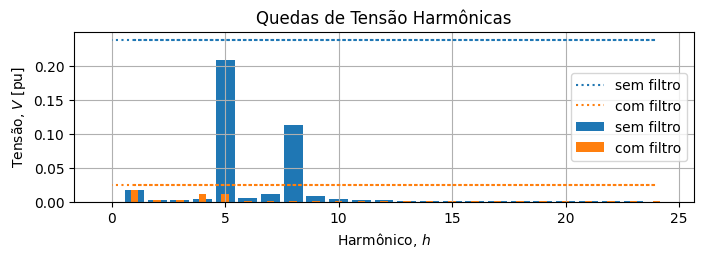

In [17]:
plt.figure(dpi=100, figsize=(16/2,9/4))
SF = vharmintSF/( V_fund/np.sqrt(3) )
totSF = np.sqrt( np.dot(SF, SF) )
plt.bar (freqint/f_fund, SF, 50/f_fund, label='sem filtro')
plt.plot(freqint/f_fund, totSF*np.ones(len(freqint)), label='sem filtro', ls=":")
CF = vharmintCF/( V_fund/np.sqrt(3) )
totCF = np.sqrt( np.dot(CF, CF) )
plt.bar (freqint/f_fund, CF, 20/f_fund, label='com filtro')
plt.plot(freqint/f_fund, totCF*np.ones(len(freqint)), label='com filtro', ls=":")
plt.grid()
plt.legend()
plt.title('Quedas de Tensão Harmônicas')
plt.xlabel('Harmônico, $h$')
plt.ylabel('Tensão, $V$ [pu]')
plt.show()

## Filtro @ $60$ Hz

### Filtro $RLC$ série

In [18]:
Ifiltro     =   ( V_fund/np.sqrt(3) ) / Zfiltro[0]
Vindutor    =    1j * X_L * Ifiltro
Vcapacitor  =   -1j * X_C * Ifiltro
Vresistor   =    R * Ifiltro

#### Potências nos Elementos do Filtro Série

In [19]:
Qcap = 3 * Vcapacitor * np.conj(Ifiltro)
Qind = 3 * Vindutor   * np.conj(Ifiltro)
Pfil = 3 * Vresistor  * np.conj(Ifiltro)
Pfil = np.real( Pfil        )
Qfil = np.imag( Qcap + Qind )

### Filtro $R \parallel L+C$

In [20]:
Yrlparalelo  = 1/R_paralelo + 1/(1j*X_L_paralelo)
Zrlparalelo  = 1/Yrlparalelo
Zfiltro2     = Zrlparalelo + 1/(1j*w_fund*C)

I_Cserie     = (V_fund/np.sqrt(3)) / Zfiltro2
V_RLparalelo = Zrlparalelo * I_Cserie
I_Rparalelo  = V_RLparalelo / R_paralelo
I_Lparalelo  = V_RLparalelo / (1j*X_L_paralelo)
V_Cserie     = 1/(1j*w_fund*C)  * I_Cserie

#### Potência nos Elementos do Filtro $R$//$L+C$

In [21]:
Qcap2 = 3 * V_Cserie     * np.conj(I_Cserie)
Qind2 = 3 * V_RLparalelo * np.conj(I_Lparalelo)
Pfil2 = 3 * Vresistor  * np.conj(Ifiltro)
Pfil2 = np.real( Pfil2         )
Qfil2 = np.imag( Qcap2 + Qind2 )

## Saídas

In [22]:
print('==========================================================')
print('     No circuito RLC série Q\u2080 =',EngNumber(FQual),' \u03B6 =',EngNumber(1/(2*FQual)) )
print('==========================================================')
print('   R    = ', EngNumber(R),'\u2126')
print('   L    = ', EngNumber(L),'H')
print('   C    = ', EngNumber(C),'F')
print('   Vcap = ', EngNumber(np.abs(Vcapacitor)), '\u2221',     EngNumber(np.round(np.angle(Vcapacitor,  deg=True),3)),'°   V')
print('   Vind = ', EngNumber(np.abs(Vindutor)),   '\u2221',     EngNumber(np.round(np.angle(Vindutor,    deg=True),3)),'°   V')
print('   Vres = ', EngNumber(np.abs(Vresistor)),  '\u2221',     EngNumber(np.round(np.angle(Vresistor,   deg=True),3)),'°   V')
temp = Vcapacitor+Vindutor+Vresistor
print('   Vtot = ', EngNumber(np.abs(temp)),       '\u2221',     EngNumber(np.round(np.angle(temp,        deg=True),3)),'°   V')
print('   Iser = ', EngNumber(np.abs(Ifiltro)),    '\u2221',     EngNumber(np.round(np.angle(Ifiltro,     deg=True),3)),'°   A')
print('   Sfil = ', EngNumber(Pfil),               'W + \u2149', EngNumber(Qfil),'VAr')
print('==========================================================')

     No circuito RLC série Q₀ = 423.11  ζ = 1.18m
   R    =  29.95m Ω
   L    =  6.86m H
   C    =  42.72u F
   Vcap =  20.78k ∡ -29m °   V
   Vind =  865.65 ∡ 179.97 °   V
   Vres =  10.02 ∡ 89.97 °   V
   Vtot =  19.92k ∡ -0 °   V
   Iser =  334.70 ∡ 89.97 °   A
   Sfil =  10.07k W + ⅉ -20M VAr


In [23]:
print('==========================================================')
print('     No circuito R//L+C, Q\u2080 =',EngNumber(FQual),' \u03B6 =',EngNumber(1/(2*FQual)) )
print('==========================================================')    
print('   Rpar         = ', EngNumber(R_paralelo),'\u2126')
print('   Lpar         = ', EngNumber(L_paralelo),'H')
print('   Cser         = ', EngNumber(C),'F')
print('   V_Cserie     = ', EngNumber(np.abs(V_Cserie)),     '\u2221',     EngNumber(np.round(np.angle(V_Cserie,     deg=True), 2)),'°   V')
print('   Vindparalelo = ', EngNumber(np.abs(V_RLparalelo)), '\u2221',     EngNumber(np.round(np.angle(V_RLparalelo, deg=True), 2)),'°   V')
print('   Vresparalelo = ', EngNumber(np.abs(V_RLparalelo)), '\u2221',     EngNumber(np.round(np.angle(V_RLparalelo, deg=True), 2)),'°   V')
temp = V_Cserie + V_RLparalelo
print('   Vtot         = ', EngNumber(np.abs(temp)),            '\u2221',     EngNumber(np.round(np.angle(temp,            deg=True), 2)),'°   V')

print('   Iindparalelo = ', EngNumber(np.abs(I_Lparalelo)),  '\u2221',     EngNumber(np.round(np.angle(I_Lparalelo,  deg=True), 2)),'°   A')
print('   Iresparalelo = ', EngNumber(np.abs(I_Rparalelo)),  '\u2221',     EngNumber(np.round(np.angle(I_Rparalelo,  deg=True), 2)),'°   A')
print('   I_Cserie     = ', EngNumber(np.abs(I_Cserie)),     '\u2221',     EngNumber(np.round(np.angle(I_Cserie,     deg=True), 2)),'°   A')
temp = I_Lparalelo + I_Rparalelo
print('   Itot         = ', EngNumber(np.abs(temp)),            '\u2221',     EngNumber(np.round(np.angle(temp,            deg=True), 2)),'°   VA')
print('   Sfil2        = ', EngNumber(Pfil2),                'W + \u2149', EngNumber(Qfil2)                                        ,'VAr')
print('==========================================================')

     No circuito R//L+C, Q₀ = 423.11  ζ = 1.18m
   Rpar         =  223.36 Ω
   Lpar         =  6.86m H
   Cser         =  42.72u F
   V_Cserie     =  20.78k ∡ -30m °   V
   Vindparalelo =  865.71 ∡ 179.31 °   V
   Vresparalelo =  865.71 ∡ 179.31 °   V
   Vtot         =  19.92k ∡ 0 °   V
   Iindparalelo =  334.67 ∡ 89.31 °   A
   Iresparalelo =  3.88 ∡ 179.31 °   A
   I_Cserie     =  334.70 ∡ 89.97 °   A
   Itot         =  334.70 ∡ 89.97 °   VA
   Sfil2        =  10.07k W + ⅉ -20M VAr


## Largura de faixa

In [24]:
w0 = 1 / np.sqrt(L*C)
Q0 = w0*L/R
BW = w0 / Q0
w1 = w0 - BW/2
w2 = w0 + BW/2

print('======================================================================')
print('   R = ',EngNumber(R),'\u2126    Q\u2080 = ', EngNumber(FQual),'  \u03B6 = ',EngNumber(1/(2*FQual)) )
print('======================================================================')    
print('Fator de qualidade           = ', EngNumber(Q0) )
print('Fator de amortecimento       = ', EngNumber(1/(2*Q0)) )
print('Frequência de ressonância    = ', EngNumber(w0/(2*np.pi)), 'Hz')
print('Frequências de meia potência = ', EngNumber(w1/(2*np.pi)), 'Hz e ', EngNumber(w2/(2*np.pi)), 'Hz')
print('======================================================================')

   R =  29.95m Ω    Q₀ =  423.11   ζ =  1.18m
Fator de qualidade           =  423.11
Fator de amortecimento       =  1.18m
Frequência de ressonância    =  294 Hz
Frequências de meia potência =  293.65 Hz e  294.35 Hz


# Resposta em Frequência

In [25]:
f = np.arange(f_fund, nharm*f_fund, 0.1)
f = np.round(f,4) # não tire este ROUND se houverem frequencias interharmônicas
w = 2*np.pi*f

Zfiltro = R + 1j*w*L + 1/(1j*w*C)
Zmod    = np.abs(Zfiltro)
Zang    = np.angle(Zfiltro, deg=True)

X_trafo     = ( np.imag(Z_trafo)/w_fund ) * w
R_trafo     =   np.real(Z_trafo)          * np.ones(len(w))
Z_trafoFreq =   R_trafo + 1j*X_trafo

Y_filtro      = 1 / Zfiltro
Y_trafo       = 1 / Z_trafoFreq
Y_trafoFiltro = Y_filtro + Y_trafo
Z_trafoFiltro = 1 / Y_trafoFiltro

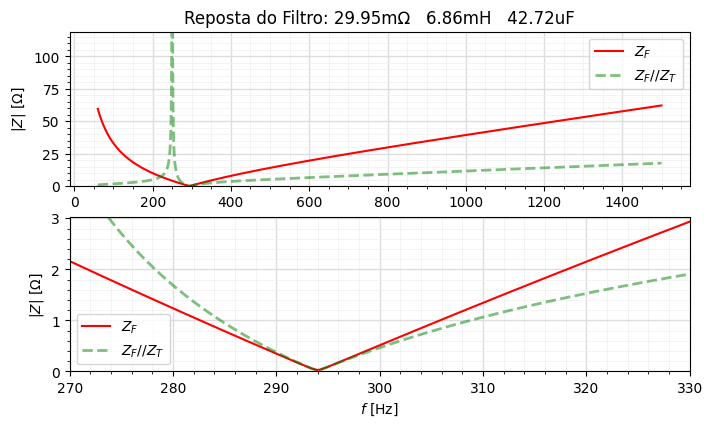

In [26]:
fig, axs = plt.subplots(2, 1)
fig.dpi = 100
fig.set_size_inches(16/2, 9/2)

leg = '$Z_{F}$'
axs[0].plot(f, Zmod, label=leg, color='red')
leg = '$Z_{F}$//$Z_{T}$'
axs[0].plot(f, np.abs(Z_trafoFiltro), label=leg, lw=2, alpha=0.5, color='green', ls='--')
axs[0].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[0].minorticks_on()
axs[0].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[0].set_ylabel('$|Z|$ [$\Omega$]')
#axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[0].set_xlabel('$f$ [Hz]')
axs[0].set_ylim(0, np.abs(2*Zfiltro[0]))
axs[0].legend()
leg = 'Reposta do Filtro: '+str(EngNumber(R))+'\u2126   '+str(EngNumber(L))+'H   '+str(EngNumber(C))+'F'
axs[0].set_title(leg)


leg = '$Z_{F}$'
axs[1].plot(f, Zmod, label=leg, color='red')
leg = '$Z_{F}$//$Z_{T}$'
axs[1].plot(f, np.abs(Z_trafoFiltro), label=leg, lw=2, alpha=0.5, color='green', ls='--')
axs[1].grid(which='major', color='#DDDDDD', linewidth=1.0)
axs[1].minorticks_on()
axs[1].grid(which='minor', color='#EEEEEE', linewidth=0.5)
axs[1].set_ylim(0, np.abs(3*Z_trafoFiltro[0]))
axs[1].set_xlim(f_fund*(h_filtrar-1/2), f_fund*(h_filtrar+1/2))
axs[1].set_ylabel('$|Z|$ [$\Omega$]')
#axs[1].plot(f, np.abs(Z_trafoFreq), label='trafo', ls='--', color='black')
axs[1].set_xlabel('$f$ [Hz]')
axs[1].legend(loc='best')
f1 = w1/(2*np.pi)
f2 = w2/(2*np.pi)
plt.show()

In [27]:
f.size

14400

In [28]:
iharmF.size

24